# Linjär algebra
Linjär algebra används för att beskriva och kombinera data med hjälp av vektorer och matriser. Det ligger bland annat till grund för linjär regression, maskininlärning och många av de beräkningar som utförs av NumPy och scikit-learn.

### Vektorer
En vektor är en ordnad samling tal:  
$v = (v₁, v₂, …, vₙ)$

Ordningen spelar roll. Vektorerna (3, 4) och (4, 3) är därför inte samma vektor.  
En vektor kan tolkas på flera sätt:  
- som en pil med riktning och längd
- som koordinater för en punkt
- som en rad med observationer eller egenskaper
- som värdena för en datapunkt i ett dataset

Vektorns längd kallas också dess norm. För en tvådimensionell vektor kan den beräknas med Pythagoras sats:
$‖v‖ = √(v₁² + v₂²)$  
En enhetsvektor pekar i samma riktning som den ursprungliga vektorn men har längden 1. Den fås genom att dividera vektorn med dess längd:  
$enhetsvektor = v / ‖v‖$

### Skalning och addition
När en vektor multipliceras med ett tal multipliceras varje komponent med samma tal. Detta ändrar vektorns längd och kan även vända riktningen om talet är negativt.  
Vektorer med lika många komponenter kan adderas komponent för komponent:  
(a₁, a₂) + (b₁, b₂) = (a₁ + b₁, a₂ + b₂)
I dataanalys används sådana kombinationer exempelvis när flera variabler vägs samman.

### Skalärprodukt
Skalärprodukten, även kallad prickprodukten, tar två lika långa vektorer och ger ett enda tal:  
$a · b = a₁b₁ + a₂b₂ + … + aₙbₙ$
När båda vektorerna är nollskilda berättar tecknet något om deras riktningar:  
- positiv skalärprodukt: vektorerna pekar huvudsakligen åt samma håll
- skalärprodukt lika med noll: vektorerna är vinkelräta
- negativ skalärprodukt: vektorerna pekar huvudsakligen åt motsatta håll
Skalärproduktens storlek påverkas både av riktningen och av vektorernas längder. Ett stort värde betyder därför inte automatiskt att riktningarna är nästan identiska.  

### Projektion
En projektion beskriver hur stor del av en vektor som ligger i en annan vektors riktning. Den kan liknas vid den skugga som en vektor kastar på en linje.  
Projektionen av b på en nollskild vektor a beräknas med:  
$projₐ(b) = (b · a / a · a) a$
Resultatet är en ny vektor som ligger längs samma linje som a.

### Matriser
En matris är ett rektangulärt rutnät av tal. En matris med m rader och n kolumner har formen m × n.  
När en matris A multipliceras med en vektor x kan beräkningen skrivas:  
$y = Ax$  
Om A har formen m × n måste x innehålla n komponenter. Resultatet får då m komponenter.  
Ett användbart sätt att tolka Ax är som en viktad kombination av kolumnerna i A. Komponenterna i x anger hur mycket av varje kolumn som ska användas.  

### Från matriser till regression
Vid linjär regression kan våra observationer och variabler samlas i en datamatris X. Modellens koefficienter samlas i en vektor β och de förutsagda värdena skrivs:
$ŷ = Xβ$
I verkliga data finns det vanligtvis ingen koefficientvektor som gör att modellens förutsägelser blir exakt lika med alla observerade värden.  
Minsta-kvadratmetoden söker därför den koefficientvektor som gör summan av de kvadrerade residualerna så liten som möjligt.  
En residual är skillnaden mellan ett observerat och ett förutsagt värde:  
$residual = observerat värde − förutsagt värde$  
Geometriskt kan detta ses som att den observerade vektorn projiceras på det område som kan skapas genom att kombinera datamatrisens kolumner. Du behöver inte behärska den fullständiga geometriska tolkningen ännu, men den förklarar varför projektioner och matriser dyker upp i regression.

![Beskrivning av bilden](lesson16.png)

# Linjär regression


### Modellen
En enkel linjär regressionsmodell kan skrivas:    
$ŷ = b₀ + b₁x$  
Symbolen ŷ, som uttalas ”y-hatt”, är modellens förutsagda värde.  
- x är den förklarande variabeln.
- ŷ är modellens förutsägelse av responsvariabeln.
- b₀ är skärningen eller interceptet.
- b₁ är lutningen eller koefficienten framför x.

Skärningen beskriver modellens förväntade värde när x = 0. Den är bara meningsfull om noll är ett rimligt värde för den förklarande variabeln.  
Lutningen beskriver hur mycket det förväntade värdet på responsvariabeln förändras när x ökar med en enhet. Det är en genomsnittlig förändring enligt modellen, inte ett löfte om hur varje enskild observation kommer att förändras.  
Regression visar inte i sig att förändringen i x orsakar förändringen i y.  

### Residualer och minsta kvadrat
Ett förutsagt värde ligger sällan exakt på det observerade värdet. Skillnaden kallas residual:  
$residual = observerat värde − förutsagt värde$  
eller:  
$e = y − ŷ$
En positiv residual betyder att observationen ligger över regressionslinjen. En negativ residual betyder att den ligger under linjen.
Minsta-kvadratmetoden väljer den linje som gör summan av de kvadrerade residualerna så liten som möjligt:  
$summa av (y − ŷ)²$  
Residualerna kvadreras bland annat för att positiva och negativa avvikelser inte ska ta ut varandra. Kvadreringen gör också att stora avvikelser får större betydelse.

### Residualdiagrammet
Ett residualdiagram används för att undersöka om en rak linje verkar vara en rimlig beskrivning av sambandet.  
I ett välfungerande enkelt fall ligger residualerna oregelbundet utspridda runt noll utan ett tydligt mönster.  
Några mönster att vara uppmärksam på:  
- En böjd form kan tyda på att sambandet inte är linjärt.
- En trattliknande form kan tyda på att residualernas spridning förändras.
- Enstaka punkter långt från övriga observationer kan behöva undersökas närmare.
- Ett tydligt mönster kan betyda att modellen saknar viktig information.  
Ett residualdiagram kan uppmärksamma problem, men det bevisar inte att modellen är korrekt.

### R² och förklarad variation
R² jämför regressionsmodellen med en enkel baslinje som alltid förutsäger responsvariabelns medelvärde.  
Ett R² på exempelvis 0,77 innebär att modellen, i det analyserade datasetet, förklarar ungefär 77 procent av variationen i responsvariabeln jämfört med denna baslinje.  
R² berättar däremot inte:  
- att modellen är korrekt
- att sambandet är ett orsakssamband
- att 77 procent av alla prognoser är rätt
- att modellen kommer fungera lika bra på nya data
- om residualerna innehåller systematiska mönster  

Det finns ingen universell gräns för vad som är ett bra R². Bedömningen beror på området, datan och analysens syfte.  
Ett större stickprov ger vanligtvis mer precisa skattningar av koefficienterna, men det gör inte automatiskt R² högre. R² påverkas av hur starkt sambandet är och hur mycket variation som finns runt modellen.  

### Anpassning och utvärdering
När LinearRegression används har några delar särskilda roller:  
- fit(X, y) anpassar modellen till data.
- intercept_ innehåller den skattade skärningen.
- coef_ innehåller modellens skattade koefficienter.
- predict(X_new) gör prognoser för nya värden.
- score(X, y) beräknar R².

Ett R² som beräknas på samma data som modellen tränades på beskriver hur väl modellen passar just dessa data. För att bedöma hur väl modellen fungerar på nya observationer behöver den senare utvärderas på data som inte användes vid träningen.

### Interpolation och extrapolation
En prognos inom det område som finns representerat i träningsdatan kallas interpolation.  
En prognos utanför det observerade området kallas extrapolation. Om modellen exempelvis tränas på värden mellan 0 och 20 är en prognos vid 37 en extrapolation.  
Sådana prognoser är mer osäkra eftersom vi antar att det linjära sambandet fortsätter utanför det område vi faktiskt har observerat.  Modellen kan beräkna ett värde, men det betyder inte att värdet är rimligt i verkligheten.  
En regressionsprognos beskriver dessutom modellens förväntade eller typiska värde. Enskilda observationer kan ligga både över och under prognosen.  

# Linjär regressionsmodell

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

Slumpgenererad data, EJ VIKTIGT

In [ ]:
n_rows = 120
true_intercept = 10.0 # skärningen y-axeln
true_slope = 2.5 # linjens lutning
true_noise_sd = 8.0
# X = Studietimmar, jämnt slumpade mellan 0, 20 
hours = np.random.uniform(0, 20, size=n_rows)
noise = np.random.normal(loc=0, scale=true_noise_sd, size=n_rows)

# Y = sann linje + brus. 10 + 2.5X + brus
score = true_intercept + true_slope * hours + noise
df = pd.DataFrame({
    'study_hours': hours,
    'exam_score': score
})
df.head()

,study_hours,exam_score
0,7.490802,23.110581
1,19.014286,54.914418
2,14.639879,43.462832
3,11.973170,28.224805
4,3.120373,20.169894


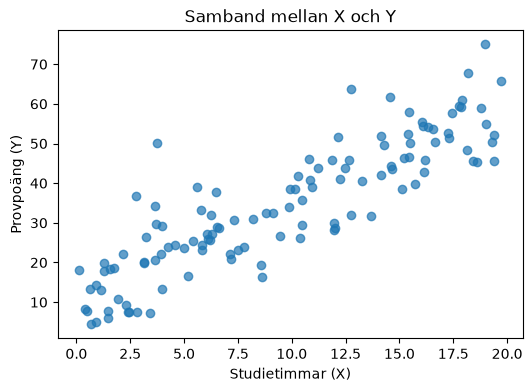

In [13]:
plt.figure(figsize=(6,4))
plt.scatter(df['study_hours'], df['exam_score'], alpha=0.7)
plt.xlabel('Studietimmar (X)')
plt.ylabel('Provpoäng (Y)')
plt.title('Samband mellan X och Y')
plt.show()

$$\widehat{Y} = \hat{a} + \hat{b}\,X$$

$$
\hat{\beta} = 
\begin{bmatrix}\hat{a}\\ \hat{b}\end{bmatrix}
= (X^\top X)^{-1} X^\top y
$$

### Om du vill räkna ut detta själv... (gör inte det) det finns färdiga funktioner som är mycket smidigare

In [17]:
x_values = df['study_hours'].values
y_values = df['exam_score'].values

# bygg upp designmatrisen: [1, x]
ones_column = np.ones_like(x_values)
design_matrix = np.column_stack([ones_column, x_values])

transposed_design = design_matrix.T
gram_matrix = transposed_design @ design_matrix
design_response = transposed_design @ y_values

beta_hat_vector = np.linalg.inv(gram_matrix) @ design_response
intercept_hat = float(beta_hat_vector[0])
slope_hat = float(beta_hat_vector[1])

print('Skärningspunkt Y-axel', intercept_hat,'\nLinjens lutning:',slope_hat)

Skärningspunkt Y-axel 11.403382739651784 
Linjens lutning: 2.4054380947183556


In [18]:
y_hat_values = intercept_hat + slope_hat * x_values
residual_values = y_values - y_hat_values

y_hat_values[:5], residual_values[:5]

(array([29.42204414, 57.14107094, 46.61870499, 40.20410121, 18.90924636]),
 array([ -6.31146295,  -2.22665279,  -3.15587313, -11.97929659,
          1.26064787]))

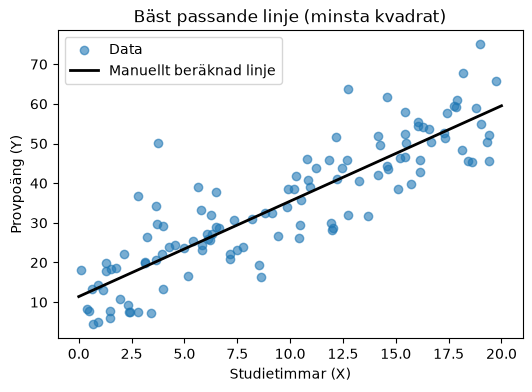

In [21]:
plt.figure(figsize=(6,4))
plt.scatter(x_values, y_values, alpha=0.6, label='Data')
grid_x = np.linspace(0, 20, 200)
grid_y_manual = intercept_hat + slope_hat * grid_x
plt.plot(grid_x, grid_y_manual, color='black', linewidth=2,label='Manuellt beräknad linje')

plt.xlabel('Studietimmar (X)')
plt.ylabel('Provpoäng (Y)')
plt.title('Bäst passande linje (minsta kvadrat)')
plt.legend()
plt.show()


Skattad skärning (â) = 11.40
Skattad lutning (beta) = 2.41 poäng per timme
R^2 (förklarad andel) = 0.769


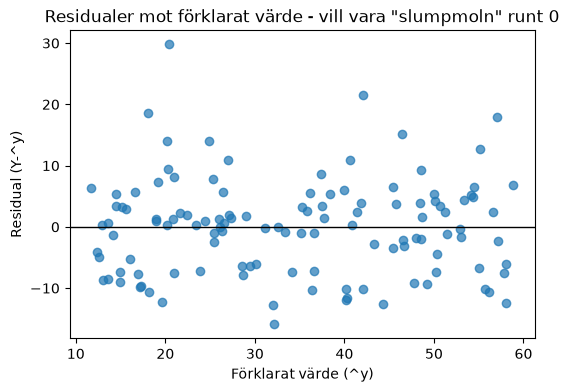

In [22]:
total_sum_of_squares = np.sum((y_values - y_values.mean())**2)
residual_sum_of_squares = np.sum(residual_values**2)

r_squared = 1 - residual_sum_of_squares / total_sum_of_squares
print(f'Skattad skärning (â) = {intercept_hat:.2f}')
print(f'Skattad lutning (beta) = {slope_hat:.2f} poäng per timme')
print(f'R^2 (förklarad andel) = {r_squared:.3f}')

plt.figure(figsize=(6,4))
plt.scatter(y_hat_values, residual_values, alpha=0.7)
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Förklarat värde (^y)')
plt.ylabel('Residual (Y-^y)')
plt.title('Residualer mot förklarat värde - vill vara "slumpmoln" runt 0')
plt.show()


In [30]:
def calculate_score(hours_query):
    y_hat = intercept_hat + slope_hat * hours_query
    return round(y_hat,1)

print(f'Prognos vid 3 timmar {calculate_score(3)}')
print(f'Prognos vid 5 timmar {calculate_score(5)}')
print(f'Prognos vid 12 timmar {calculate_score(12)}')
print(f'Prognos vid 20 timmar {calculate_score(20)}')

Prognos vid 3 timmar 18.6
Prognos vid 5 timmar 23.4
Prognos vid 12 timmar 40.3
Prognos vid 20 timmar 59.5


# Färdiga metoder (använd dessa):

In [31]:
from sklearn.linear_model import LinearRegression

x_2d = df[['study_hours']].values
y_1d = df['exam_score'].values

linreg = LinearRegression()
linreg.fit(x_2d, y_1d)

sk_intercept = float(linreg.intercept_)
sk_slope = float(linreg.coef_[0])
sk_r2 = float(linreg.score(x_2d, y_1d))
sk_pred_12 = float(linreg.predict(np.array([[12.0]]))[0])

print(f'''
sklearn:
    intercept (Y-axelns skärningspunkt) = {sk_intercept:.2f}
    slope (linjens lutning) = {sk_slope:.2f}
    R^2 (Förklaringsgrad, determinationskoefficient) = {sk_r2:.3f}
    prognos vid 12 timmar = {sk_pred_12:.1f} 
''')


sklearn:
    intercept (Y-axelns skärningspunkt) = 11.40
    slope (linjens lutning) = 2.41
    R^2 (Förklaringsgrad, determinationskoefficient) = 0.769
    prognos vid 12 timmar = 40.3 

